# Zenodo 1,053: neighbourhoods, cross-family enrichment and map-proposed candidates (2026-10-24)

Follows [`zenodo_1053_consensus_261024`](zenodo_1053_consensus_261024.ipynb). The density groups there are the tightest places in z, and the tightest places are mostly single sources. This notebook asks three questions those groups cannot answer:

1. What is lost by setting aside the recordings HDBSCAN leaves unassigned?
2. Which source families are nearer each other in z than their sizes and nested windows explain?
3. Which regions a reader sees on the 2-D map are real neighbourhoods in feature space, and which of them cross sources and sizes?

It also reports stability as a continuous quantity with its uncertainty, so that groups near the 0.75 convention can be judged rather than cut.

Everything is computed in `research/zenodo/atlas/neighbourhood_atlas.py` (config `configs/analysis/zenodo-neighbourhoods-261024.yaml`) from cached z; pyspi is not run. Co-location means a shared dependence-organisation signature; nested windows of one recording are never counted as independent support.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform
import yaml
from IPython.display import display
from threadpoolctl import threadpool_limits
from research.zenodo.atlas import consensus_atlas as ca
from research.zenodo.atlas import neighbourhood_atlas as na
from research.zenodo.atlas import tsne_atlas as ta
%matplotlib inline

ta.notebook_style()
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 220)
config = yaml.safe_load(na.CONFIG.read_text())
cons = yaml.safe_load((ROOT / config["consensus"]).read_text())
base = yaml.safe_load((ROOT / config["base"]).read_text())
OUT = ROOT / config["output"]
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
if not (OUT / "manifest.json").exists():
    with threadpool_limits(limits=config["threads"]):
        na.compute(config, OUT)  # about 5 minutes on 8 cores
N = na.load(OUT)
C = ca.load(ROOT / cons["output"])
corpus = ta.load_corpus(base)
meta = corpus["meta"]
density, regions = N["arrays"]["density"], N["arrays"]["regions"]
groups = C["groups"].set_index("group")
xy = C["arrays"][f"map__{N['manifest']['chosen_map']}"][0]
scores = ta.load(ROOT / base["output"])["arrays"]["scores_primary"]
D = squareform(pdist(scores[:, :config["analysis_dims"]]))
src, dst = N["arrays"]["edges_k10"]
print(f"{len(meta)} recordings, {meta.parent.nunique()} parent recordings, {meta.source.nunique()} source families; "
      f"{int((density >= 0).sum())} in a density group, {int((regions >= 0).sum())} in a map region "
      f"({regions.max() + 1} regions on {N['manifest']['chosen_map']})")

1053 recordings, 688 parent recordings, 40 source families; 452 in a density group, 833 in a map region (53 regions on pca50-p50-x1)


## 1. The unassigned recordings

HDBSCAN's noise label means "not in a dense core at this setting". It is not "bad data" and not "outlier". A recording becomes noise when it sits between cores or in a sparse part of the continuum, and the label moves with `min_cluster_size` and `min_samples` (Campello et al. 2013). Removing noise therefore removes the continuum, not errors.

That is fine for one narrow purpose: choosing exemplars from cores. It is wrong in two places:

- **In a figure**, removing noise hides the majority of the corpus and makes the remaining groups look more separated than they are. The old figure did this.
- **In any statement about the corpus**, removing noise changes what is being described.

The check below asks where the unassigned recordings' feature-space neighbours are (10 nearest, other parents only).

In [2]:
in_group = density >= 0
share_to_group = pd.Series(in_group[dst]).groupby(src).mean().reindex(range(len(meta))).to_numpy()
own = pd.Series(density[dst] == density[src]).groupby(src).mean().reindex(range(len(meta))).to_numpy()
rows = []
for label, mask in [("in a density group", in_group), ("unassigned", ~in_group)]:
    rows.append({"recordings": label, "n": int(mask.sum()), "share of corpus": mask.mean(),
                 "neighbours in some group": np.nanmean(share_to_group[mask]),
                 "neighbours in own group": np.nanmean(own[mask]) if label != "unassigned" else np.nan,
                 "with ≥ 5 of 10 neighbours in groups": np.mean(share_to_group[mask] >= .5)})
noise = pd.DataFrame(rows).set_index("recordings")
print(f"Unassigned on the chosen map's 2-D regions: {np.mean(regions < 0):.0%}")
noise.round(2)

Unassigned on the chosen map's 2-D regions: 21%


,n,share of corpus,neighbours in some group,neighbours in own group,with ≥ 5 of 10 neighbours in groups
recordings,,,,,
in a density group,452,0.43,0.86,0.8,0.96
unassigned,601,0.57,0.46,NaN,0.51


## 2. Stability as a quantity, not a gate

Hennig's (2007) reading of the cluster-wise Jaccard is a rule of thumb:

| mean Jaccard | reading |
|---|---|
| ≥ 0.85 | highly stable |
| ≥ 0.75 | stable |
| 0.6–0.75 | indicates a pattern, but which points belong to it is doubtful |
| < 0.6 | not to be trusted |

The consensus pool used 0.75. Below, each density group's mean is shown with its Monte Carlo error, which is the precision of a 50-replicate mean (± 2 SE). It is also shown with the 10–90% spread of the replicate values, which is how often the group partly dissolves.

The columns on the right re-find each group under other HDBSCAN settings and analysis dimensions. Each value is the best Jaccard match; 1 means the same group.

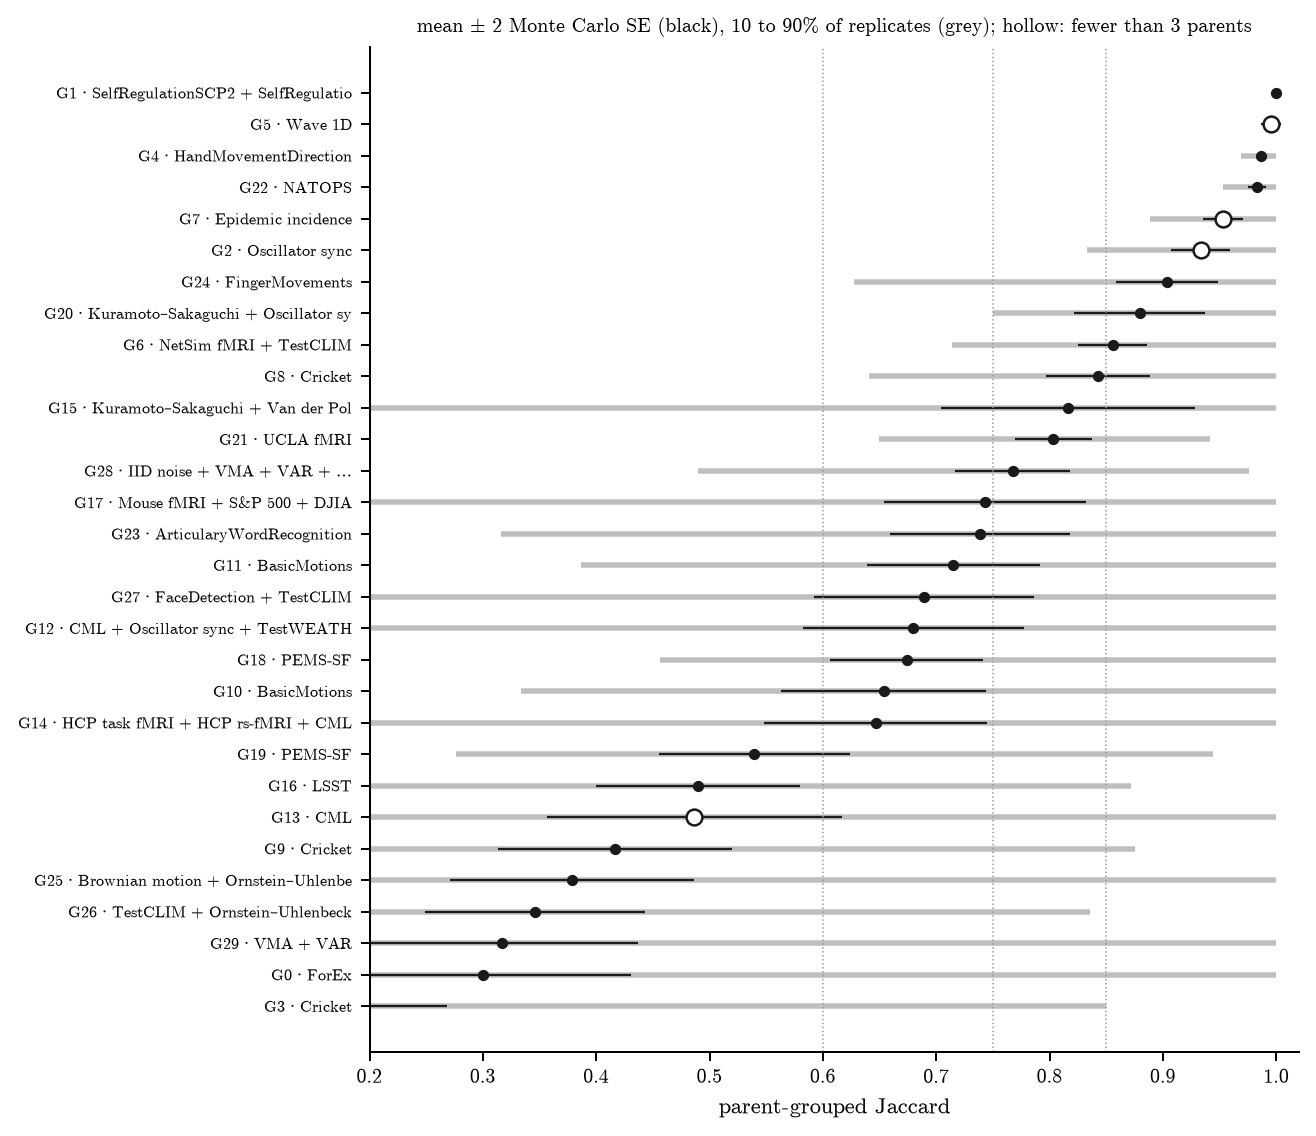

,group,stability,mc_2se,q10,q90,title,size,parents,sources,origin,size_survival,tier,mcs4-ms4,mcs5-ms3,mcs8-ms5,mcs10-ms5,PCA20,PCA100,band
1,1,1.00,0.00,1.00,1.00,SelfRegulationSCP2 + SelfRegulationSCP1,39,39,2,real,0.65,1,1.00,1.00,1.00,1.00,1.00,0.97,≥ .85
5,5,1.00,0.01,1.00,1.00,Wave 1D,5,1,1,synthetic,0.77,3,1.00,0.83,0.00,0.00,0.00,1.00,≥ .85
4,4,0.99,0.00,0.97,1.00,HandMovementDirection,39,39,1,real,0.93,1,0.98,1.00,1.00,1.00,1.00,0.98,≥ .85
22,22,0.98,0.01,0.95,1.00,NATOPS,33,33,1,real,0.45,1,1.00,1.00,1.00,1.00,0.94,1.00,≥ .85
7,7,0.95,0.02,0.89,1.00,Epidemic incidence,8,1,1,real,0.97,3,0.89,1.00,1.00,0.00,1.00,0.89,≥ .85
2,2,0.93,0.03,0.83,1.00,Oscillator sync,5,1,1,synthetic,0.90,3,0.71,0.71,0.00,0.00,1.00,0.00,≥ .85
24,24,0.90,0.04,0.63,1.00,FingerMovements,13,13,1,real,0.38,1,0.81,0.81,1.00,1.00,1.00,0.92,≥ .85
20,20,0.88,0.06,0.75,1.00,Kuramoto–Sakaguchi + Oscillator sync + Seismogram,18,5,3,mixed,0.91,1,0.89,0.86,1.00,1.00,0.68,0.80,≥ .85
6,6,0.86,0.03,0.71,1.00,NetSim fMRI + TestCLIM,15,14,2,synthetic,0.90,1,0.74,0.67,1.00,1.00,0.67,0.53,≥ .85
8,8,0.84,0.05,0.64,1.00,Cricket,10,10,1,real,-0.05,1,0.91,0.83,1.00,1.00,0.90,0.75,.75–.85


In [3]:
J = N["arrays"]["density_jaccard"]
stab = pd.DataFrame({"group": np.unique(density[density >= 0]), "stability": np.nanmean(J, 0),
                     "mc_2se": 2 * np.nanstd(J, 0, ddof=1) / np.sqrt(np.sum(~np.isnan(J), 0)),
                     "q10": np.nanquantile(J, .1, 0), "q90": np.nanquantile(J, .9, 0)})
info = groups[["title", "size", "parents", "sources", "origin", "size_survival", "tier"]]
stab = stab.join(info, on="group").merge(N["robustness"], on="group").sort_values("stability", ascending=False)
stab["band"] = pd.cut(stab.stability, [0, .6, .75, .85, 1.01], right=False, labels=["< .6", ".6–.75", ".75–.85", "≥ .85"])
fig, ax = plt.subplots(figsize=(7.2, 6.2))
y = np.arange(len(stab))[::-1]
ax.hlines(y, stab.q10, stab.q90, color="0.75", lw=2.2)
ax.errorbar(stab.stability, y, xerr=stab.mc_2se, fmt="o", ms=3.5, color="0.1", ecolor="0.1", elinewidth=.9, capsize=0)
ax.scatter(stab.stability[stab.parents < 3], y[(stab.parents < 3).to_numpy()], s=40, facecolors="white", edgecolors="0.1", zorder=3)
for x in (.6, .75, .85):
    ax.axvline(x, color="0.6", lw=.6, ls=":")
ax.set(yticks=y, yticklabels=[f"G{g} · {t[:34]}" for g, t in zip(stab.group, stab.title)], xlabel="parent-grouped Jaccard",
       xlim=(.2, 1.02))
ax.tick_params(axis="y", labelsize=6.5)
ax.set_title(r"mean $\pm$ 2 Monte Carlo SE (black), 10 to 90% of replicates (grey); hollow: fewer than 3 parents", fontsize=8)
fig.savefig(FIGURES / "density-stability.png", dpi=300)
plt.show()
stab.round(2)

In [4]:
rows = []
for t in config["stability"]["thresholds"]:
    pool = stab[(stab.stability >= t) & (stab.parents >= 3)]
    rows.append({"threshold": t, "pool": len(pool), "with map agreement (tier-1 rule)": int(groups.loc[pool.group, "agrees_on_map"].sum()),
                 "groups": ", ".join(f"G{g}" for g in sorted(pool.group))})
pd.DataFrame(rows)

,threshold,pool,with map agreement (tier-1 rule),groups
0,0.60,18,15,"G1, G4, G6, G8, G10, G11, G12, G14, G15, G17, G18, G20, G21, G22, G23, G24, ..."
1,0.65,17,14,"G1, G4, G6, G8, G10, G11, G12, G15, G17, G18, G20, G21, G22, G23, G24, G27, G28"
2,0.70,13,12,"G1, G4, G6, G8, G11, G15, G17, G20, G21, G22, G23, G24, G28"
3,0.75,10,9,"G1, G4, G6, G8, G15, G20, G21, G22, G24, G28"
4,0.80,9,9,"G1, G4, G6, G8, G15, G20, G21, G22, G24"
5,0.85,6,6,"G1, G4, G6, G20, G22, G24"


## 3. Which source families are neighbours: enrichment

**Statistic.** Each recording keeps its 10 nearest neighbours in PCA50, skipping recordings from its own parent recording. For each pair of source families, the statistic counts the neighbour links between them.

**Null.** Family labels are shuffled across parent recordings, only among parents of similar size. A parent's size is the median log M and median log T of its recordings, binned into 3 × 3 quantile strata. The neighbour graph stays fixed throughout. Degree, nested windows and how many recordings each parent contributes are therefore preserved; only "which family is which" is randomised.

**Output.** An excess over that null means two families are neighbours more often than recordings of their sizes would be. q values are Benjamini–Hochberg-adjusted over all 820 between-family pairs, from 5,000 permutations. `parent_pairs` counts the distinct parent-recording pairs that carry the links, so a single pair of recordings cannot make a result.

In [5]:
E = N["enrichment"]
P = E[(E.k == config["enrichment"]["primary"]["k"]) & (E.bins == config["enrichment"]["primary"]["bins"])]
hits = P[(P.kind != "within") & (P.q <= .05) & (P.parent_pairs >= 2)].copy()
hits["both_multi_parent"] = (hits.parents_a >= 2) & (hits.parents_b >= 2)
hits = hits.sort_values(["both_multi_parent", "kind", "ratio"], ascending=[False, True, False])
print("Significant between-family pairs (q ≤ .05, ≥ 2 parent pairs):", hits.kind.value_counts().to_dict(),
      "| with ≥ 2 parents on both sides:", int(hits.both_multi_parent.sum()))
hits[["kind", "family_a", "family_b", "observed", "expected", "ratio", "q", "parent_pairs", "parents_a", "parents_b", "both_multi_parent"]].round(3)

Significant between-family pairs (q ≤ .05, ≥ 2 parent pairs): {'model–model': 9, 'model–real': 9, 'real–real': 7} | with ≥ 2 parents on both sides: 18


,kind,family_a,family_b,observed,expected,ratio,q,parent_pairs,parents_a,parents_b,both_multi_parent
3808,model–model,Kuramoto–Sakaguchi,Oscillator sync,79,0.854,92.463,0.012,6,3,8,True
3820,model–model,Kuramoto–Sakaguchi,Van der Pol,67,0.789,84.896,0.012,6,3,2,True
4080,model–model,VAR,VMA,493,9.970,49.447,0.012,32,6,6,True
3795,model–model,IID noise,VMA,208,8.615,24.144,0.012,21,5,6,True
3794,model–model,IID noise,VAR,173,8.769,19.729,0.026,13,5,6,True
3282,model–real,ArticularyWordRecognition,Brownian motion,46,0.885,52.001,0.018,18,14,2,True
3361,model–real,Brownian motion,Cricket,24,0.562,42.720,0.012,14,2,44,True
3619,model–real,FingerMovements,Oscillator sync,53,1.853,28.608,0.012,18,20,8,True
3786,model–real,IID noise,RacketSports,15,1.661,9.030,0.048,13,5,38,True
3353,model–real,BasicMotions,VAR,16,2.033,7.870,0.018,16,39,6,True


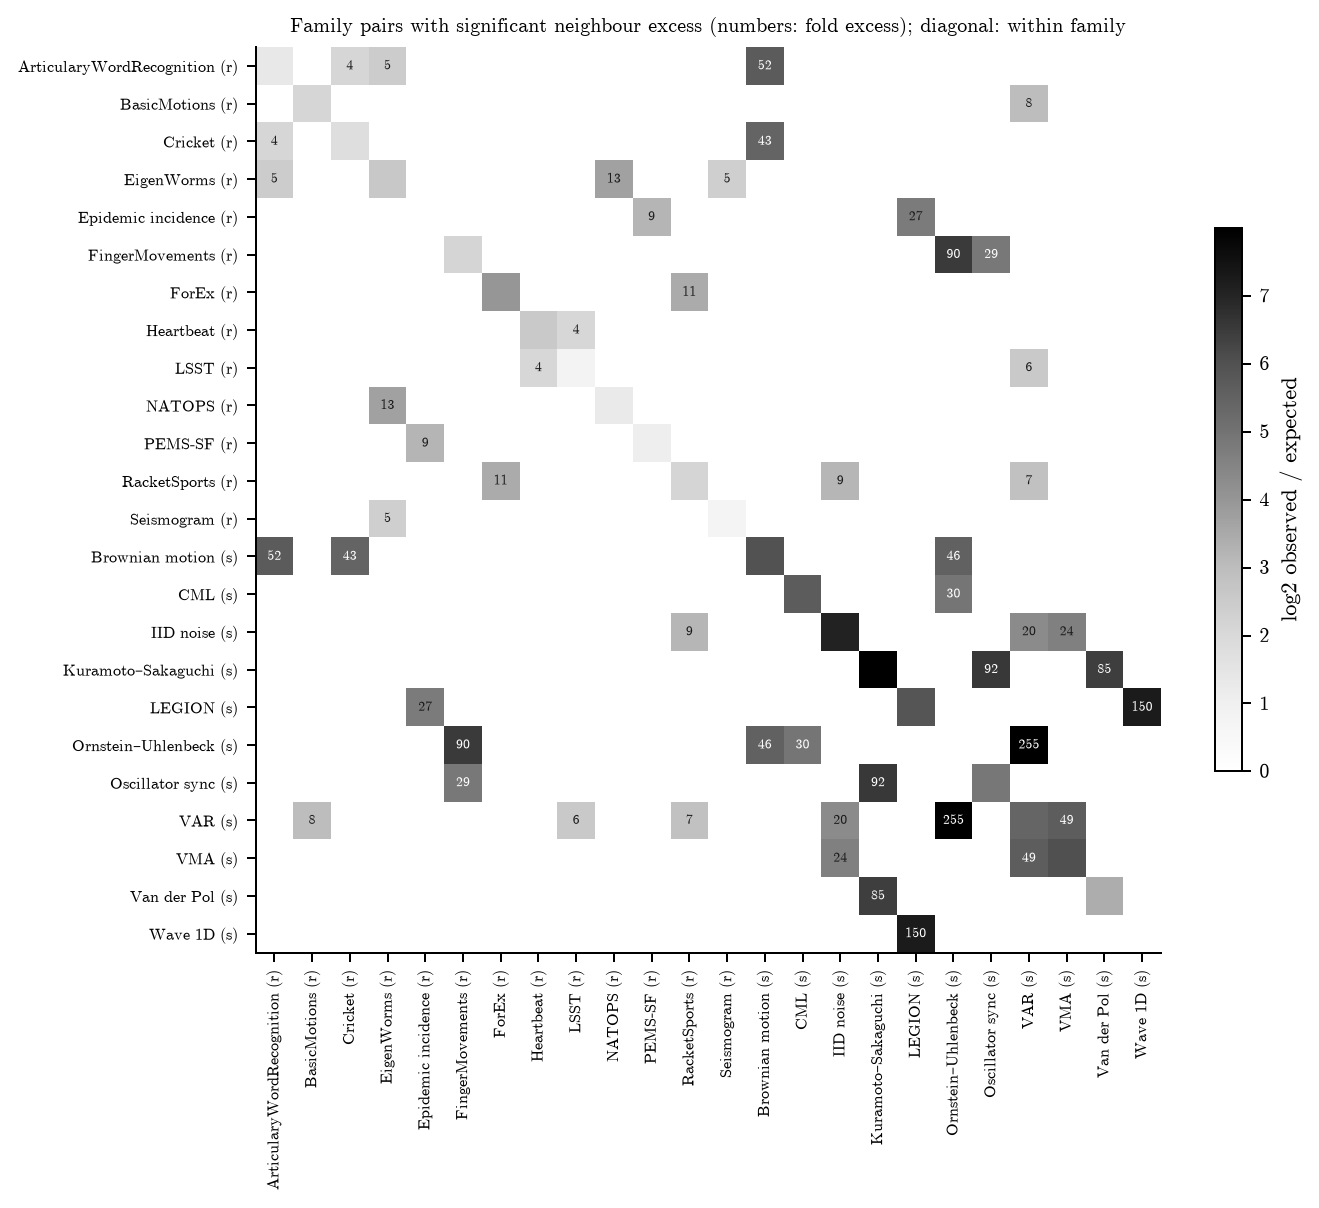

In [6]:
fams = sorted(set(hits.family_a) | set(hits.family_b))
mat = pd.DataFrame(np.nan, index=fams, columns=fams)
for r in P[P.family_a.isin(fams) & P.family_b.isin(fams)].itertuples():
    mat.loc[r.family_a, r.family_b] = mat.loc[r.family_b, r.family_a] = np.log2(r.ratio) if 0 < r.ratio < np.inf else np.nan
sig = pd.DataFrame(False, index=fams, columns=fams)
for r in hits.itertuples():
    sig.loc[r.family_a, r.family_b] = sig.loc[r.family_b, r.family_a] = True
origin = meta.groupby("source").origin.first()
order = sorted(fams, key=lambda f: (origin[f], f))
mat, sig = mat.loc[order, order], sig.loc[order, order]
fig, ax = plt.subplots(figsize=(7.4, 6.6))
shown = np.where(sig.to_numpy() | np.eye(len(order), dtype=bool), mat.to_numpy(), np.nan)
im = ax.imshow(shown, cmap="Greys", vmin=0, vmax=np.nanpercentile(shown, 98))
for i in range(len(order)):
    for j in range(len(order)):
        if sig.iloc[i, j]:
            ax.text(j, i, f"{2 ** mat.iloc[i, j]:.0f}", ha="center", va="center", fontsize=5.5,
                    color="white" if mat.iloc[i, j] > .6 * np.nanpercentile(shown, 98) else "0.1")
ax.set_xticks(range(len(order)), [f"{f} ({origin[f][0]})" for f in order], rotation=90, fontsize=6.5)
ax.set_yticks(range(len(order)), [f"{f} ({origin[f][0]})" for f in order], fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=.6, label="log2 observed / expected")
ax.set_title("Family pairs with significant neighbour excess (numbers: fold excess); diagonal: within family", fontsize=8)
fig.savefig(FIGURES / "enrichment-matrix.png", dpi=300)
plt.show()

**Sensitivity.** Below are the same pairs under other neighbourhood sizes (k) and size stratifications (bins; 0 = none). A pair that is significant without stratification but not with it is explained by size. A pair that survives every setting is the robust kind.

**Why stratification adds pairs rather than removing them.** The neighbour graph is fixed, and labels move only among parents of similar size. A pair of families of the same size therefore gets a null that already contains their size-driven affinity, which is conservative. A pair of families of different sizes gets a small expected count, because recordings of different sizes are rarely neighbours. Links between such families are then strong evidence of affinity that size does not explain. That is the pattern the claim needs, not a weakness of the test.

Families with a single parent recording (Ornstein–Uhlenbeck, Wave 1D, Epidemic incidence) rest on one generator configuration or one recording. Their pairs are listed, but they are weaker evidence.

In [7]:
key = lambda frame: frame.family_a + " · " + frame.family_b
sens = E[E.kind != "within"].assign(pair=key).pivot_table(index="pair", columns=["k", "bins"], values="q")
sens = sens.loc[key(hits)]
sens.columns = [f"k{k} b{b}" for k, b in sens.columns]
sens.insert(0, "kind", hits.kind.to_numpy())
sens.round(3)

,kind,k5 b0,k5 b3,k5 b4,k10 b0,k10 b3,k10 b4,k20 b0,k20 b3,k20 b4
pair,,,,,,,,,,
Kuramoto–Sakaguchi · Oscillator sync,model–model,0.057,0.022,0.052,0.047,0.012,0.012,0.035,0.007,0.005
Kuramoto–Sakaguchi · Van der Pol,model–model,0.057,0.022,0.341,0.039,0.012,0.233,0.026,0.007,0.094
VAR · VMA,model–model,0.057,0.022,0.022,0.039,0.012,0.012,0.026,0.007,0.005
IID noise · VMA,model–model,0.057,0.111,0.161,0.039,0.012,0.016,0.026,0.007,0.005
IID noise · VAR,model–model,0.057,0.166,0.244,0.039,0.026,0.036,0.026,0.007,0.005
ArticularyWordRecognition · Brownian motion,model–real,0.071,0.101,0.052,0.064,0.018,0.012,0.052,0.007,0.005
Brownian motion · Cricket,model–real,1.000,0.052,0.358,0.214,0.012,0.023,0.158,0.007,0.035
FingerMovements · Oscillator sync,model–real,0.218,0.022,0.022,0.159,0.012,0.012,0.110,0.007,0.005
IID noise · RacketSports,model–real,1.000,0.204,0.236,0.751,0.048,0.045,0.463,0.019,0.029


In [8]:
counts = (E[(E.kind != "within") & (E.q <= .05) & (E.parent_pairs >= 2)]
          .groupby(["k", "bins", "kind"]).size().unstack(fill_value=0))
display(counts)
named = [("Mouse fMRI", "S&P 500"), ("DJIA", "Mouse fMRI"), ("Kuramoto–Sakaguchi", "Van der Pol"), ("Kuramoto–Sakaguchi", "Seismogram"),
         ("Cricket", "ForEx"), ("LEGION", "PEMS-SF"), ("CML", "TestWEATH"), ("Brownian motion", "Cricket")]
pick = lambda a, b: ((P.family_a == a) & (P.family_b == b)) | ((P.family_a == b) & (P.family_b == a))
print("Pairs named in earlier candidates, primary setting:")
pd.concat([P[pick(a, b)] for a, b in named])[["family_a", "family_b", "observed", "expected", "ratio", "p", "q", "parent_pairs"]].round(3)

kind     model–model  model–real  real–real
k  bins                                    
5  3               4           2          2
   4               1           2          4
10 0               9           0          1
   3               9           9          7
   4               5          15         12
20 0              14           3          1
   3              17          21          9
   4               7          23         19

Pairs named in earlier candidates, primary setting:


,family_a,family_b,observed,expected,ratio,p,q,parent_pairs
3877,Mouse fMRI,S&P 500,19,3.499,5.430,0.022,0.223,11
3484,DJIA,Mouse fMRI,23,4.761,4.831,0.014,0.161,15
3820,Kuramoto–Sakaguchi,Van der Pol,67,0.789,84.896,0.000,0.012,6
3812,Kuramoto–Sakaguchi,Seismogram,47,3.393,13.852,0.007,0.117,14
3440,Cricket,ForEx,11,5.488,2.004,0.160,0.911,8
3832,LEGION,PEMS-SF,49,5.388,9.094,0.012,0.153,33
3426,CML,TestWEATH,104,23.661,4.395,0.032,0.301,38
3361,Brownian motion,Cricket,24,0.562,42.720,0.000,0.012,14


## 4. Map-proposed, feature-validated neighbourhoods

**Proposal.** Regions are HDBSCAN (5/5) on the chosen consensus map, which is what a reader would call clusters.

**Validation.** Each region is checked in PCA50, the analysis space:
- `cohesion_z`, `p_random`: tighter than random same-size sets?
- `nn_inside`: what share of members' 10 nearest neighbours (other parents) fall in the region?
- `size_survival`, `p_matched`: does its tightness survive sets from other sources matched member by member on (log M, log T)?
- `cross_members`: what share of members have a neighbour from another source inside the region? This separates real mixing from two single-source clumps that merely sit next to each other on the map.

**Stability.** `stability` re-runs the whole t-SNE map on parent-grouped subsets and re-finds the regions, so it tests the region, not one run. `recurrence` is the median best match on the other eligible maps of the sweep.

**Labels:**
- *core*: at least 80% of the region is one tier-1 or tier-2 density group;
- *neighbourhood*: cohesive (`p_random` ≤ .01), `stability` ≥ .6 and `nn_inside` ≥ .3, but not a core;
- *one parent*: windows of a single recording. Such a region is a replicate structure, not a neighbourhood;
- *map-only*: the rest. Its separation is mostly t-SNE's.

These thresholds are declared readings, not gates; all numbers are shown.

In [9]:
R = na.classify_regions(N["regions"], groups.tier)  # kind, multi-source, size heterogeneity, priority; shared with explorer v4
cols = ["region", "kind", "title", "size", "parents", "sources", "sources_2p", "origin", "M", "T", "stability", "recurrence",
        "cohesion_z", "p_random", "nn_inside", "cross_members", "size_survival", "p_matched", "in_density", "modal_group",
        "modal_group_share", "source_mix"]
print(R.kind.value_counts().to_dict(), "| multi-source (≥ 2 sources with ≥ 2 parents):", int(R.multi_source.sum()),
      "| size-heterogeneous:", int(R.size_heterogeneous.sum()))
R.sort_values(["kind", "stability"], ascending=[True, False])[cols].round(2)

{'map-only': 23, 'neighbourhood': 20, 'core': 6, 'one parent': 4} | multi-source (≥ 2 sources with ≥ 2 parents): 14 | size-heterogeneous: 40


,region,kind,title,size,parents,sources,sources_2p,origin,M,T,...,cohesion_z,p_random,nn_inside,cross_members,size_survival,p_matched,in_density,modal_group,modal_group_share,source_mix
0,0,core,SelfRegulationSCP2 + SelfRegulationSCP1,39,39,2,2,real,6–7,896–1152,...,22.15,0.0,1.00,0.38,0.65,0.00,1.00,1,1.00,SelfRegulationSCP2 20/20p; SelfRegulationSCP1 19/19p
4,4,core,HandMovementDirection + CML + HCP rs-fMRI + …,42,42,4,1,mixed,5–10,36–1200,...,24.97,0.0,0.99,0.52,0.91,0.00,0.93,4,0.93,HandMovementDirection 39/39p; CML 1/1p; HCP rs-fMRI 1/1p; LSST 1/1p
6,6,core,NATOPS + LSST + TestCLIM,40,40,3,2,mixed,5–24,36–250,...,20.49,0.0,0.95,0.32,0.48,0.00,0.82,22,0.82,NATOPS 37/37p; LSST 2/2p; TestCLIM 1/1p
25,25,core,Cricket,11,11,1,1,real,6–6,1197–1197,...,11.93,0.0,0.89,0.00,-0.07,1.00,0.91,8,0.91,Cricket 11/11p
31,31,core,FingerMovements,15,15,1,1,real,28–28,50–50,...,14.45,0.0,0.96,0.00,0.32,0.00,0.87,24,0.87,FingerMovements 15/15p
51,51,core,VMA + VAR + IID noise + …,64,15,4,4,synthetic,5–20,100–2000,...,34.44,0.0,0.98,1.00,0.94,0.00,0.91,28,0.91,VMA 26/6p; VAR 15/4p; IID noise 21/3p; Oscillator sync 2/2p
8,8,map-only,LEGION,5,2,1,1,synthetic,5–5,501–2000,...,6.82,0.0,0.24,0.00,1.12,0.00,0.00,-1,0.00,LEGION 5/2p
19,19,map-only,CML + Epidemic incidence,11,2,2,0,mixed,8–20,500–567,...,10.12,0.0,0.12,1.00,1.01,0.00,0.73,7,0.73,CML 1/1p; Epidemic incidence 10/1p
12,12,map-only,LEGION,5,2,1,1,synthetic,10–20,501–1001,...,5.65,0.0,0.16,0.00,0.81,0.00,0.00,-1,0.00,LEGION 5/2p
7,7,map-only,Oscillator hysteresis + Wave 1D,9,2,2,0,synthetic,9–25,100–1001,...,7.47,0.0,0.12,0.89,0.82,0.00,0.56,5,0.56,Oscillator hysteresis 1/1p; Wave 1D 8/1p


### Candidates for the dependence-mechanism claim

The informative groups for "z groups recordings by how their dependence is organised, across generators and sizes" are those that refute the obvious alternatives:

- **multi-source**: at least two source families, each with at least two parent recordings, so that one dataset's acquisition cannot explain the group;
- **size-heterogeneous**: M or T varies at least two-fold, so that recording size cannot explain it;
- **validated** in feature space.

Below are map regions and density groups (any stability) meeting at least one of the first two criteria, ranked by evidence.

In [10]:
cand_r = R[R.kind.isin(["core", "neighbourhood"]) & ((R.sources >= 2) | R.size_heterogeneous)].copy()
cand_r["unit"] = "R" + cand_r.region.astype(str)
G = groups.reset_index()
per_source = lambda g: meta[density == g].groupby("source").parent.nunique()
G["sources_2p"] = [int((per_source(g) >= 2).sum()) for g in G.group]
G["size_heterogeneous"] = [(meta["M"][density == g].max() / meta["M"][density == g].min() >= 2) or
                           (meta["T"][density == g].max() / meta["T"][density == g].min() >= 2) for g in G.group]
cand_g = G[((G.sources >= 2) | G.size_heterogeneous) & (G.stability >= .6)].copy()
cand_g["unit"] = "G" + cand_g.group.astype(str)
cand_g["kind"] = cand_g.tier.map({1: "tier 1", 2: "tier 2", 3: "tier 3"})
cand_g["covered_by"] = [next((f"R{r}" for r in cand_r.region if np.mean(regions[density == g] == r) >= .8), None) for g in cand_g.group]
cols = ["unit", "level", "kind", "title", "size", "parents", "sources", "sources_2p", "size_heterogeneous", "M", "T", "stability",
        "size_survival", "nn_inside", "cross_members", "covered_by", "source_mix"]
show = pd.concat([cand_r.assign(level="map region", covered_by=None), cand_g.assign(level="density group", nn_inside=np.nan, cross_members=np.nan)])[cols]
show.insert(2, "priority", na.priority(show))
show = show.sort_values(["priority", "stability"], ascending=[True, False]).reset_index(drop=True)
print(show.priority.value_counts().sort_index().to_dict())
show.round(2)

{'A multi-source, size-heterogeneous': 12, 'B multi-source': 2, 'C second source from one parent': 13, 'D size-heterogeneous only': 4}


,unit,level,priority,kind,title,size,parents,sources,sources_2p,size_heterogeneous,M,T,stability,size_survival,nn_inside,cross_members,covered_by,source_mix
0,R11,map region,"A multi-source, size-heterogeneous",neighbourhood,Mouse fMRI + DJIA + S&P 500 + …,20,20,6,4,True,6–15,36–2000,0.99,0.93,0.88,0.95,None,Mouse fMRI 9/9p; DJIA 4/4p; S&P 500 3/3p; LSST 2/2p; Heartbeat 1/1p; UCLA fM...
1,R6,map region,"A multi-source, size-heterogeneous",core,NATOPS + LSST + TestCLIM,40,40,3,2,True,5–24,36–250,0.94,0.48,0.95,0.32,None,NATOPS 37/37p; LSST 2/2p; TestCLIM 1/1p
2,R34,map region,"A multi-source, size-heterogeneous",neighbourhood,Kuramoto–Sakaguchi + Van der Pol + Oscillator hysteresis,12,6,3,2,True,5–25,500–1001,0.83,1.04,0.63,1.00,None,Kuramoto–Sakaguchi 7/3p; Van der Pol 4/2p; Oscillator hysteresis 1/1p
3,G28,density group,"A multi-source, size-heterogeneous",tier 2,IID noise + VMA + VAR + …,86,19,6,4,True,10–20,100–2000,0.77,0.87,NaN,NaN,NaN,IID noise 29; VMA 28; VAR 18; Oscillator sync 9; CML 1; TestCLIM 1
4,R27,map region,"A multi-source, size-heterogeneous",neighbourhood,HCP task fMRI + HCP rs-fMRI + Brownian motion + …,15,14,5,2,True,5–25,250–1200,0.76,0.98,0.69,1.00,None,HCP task fMRI 6/6p; HCP rs-fMRI 5/5p; Brownian motion 2/1p; CML 1/1p; TestCL...
5,G17,density group,"A multi-source, size-heterogeneous",tier 3,Mouse fMRI + S&P 500 + DJIA,10,10,3,3,True,8–14,481–2000,0.74,0.95,NaN,NaN,R11,Mouse fMRI 5; S&P 500 3; DJIA 2
6,R28,map region,"A multi-source, size-heterogeneous",neighbourhood,ArticularyWordRecognition + DJIA + Brownian motion + …,18,17,6,2,True,6–16,100–3000,0.74,1.00,0.84,1.00,None,ArticularyWordRecognition 10/10p; DJIA 3/3p; Brownian motion 2/1p; Cricket 1...
7,R43,map region,"A multi-source, size-heterogeneous",neighbourhood,TestWEATH + VAR + VMA,21,7,3,3,True,5–20,500–2000,0.73,0.84,0.69,1.00,None,TestWEATH 3/3p; VAR 5/2p; VMA 13/2p
8,R5,map region,"A multi-source, size-heterogeneous",neighbourhood,TestWEATH + CML + Oscillator sync,19,10,3,2,True,5–20,100–1000,0.70,-0.03,0.81,1.00,None,TestWEATH 6/6p; CML 12/3p; Oscillator sync 1/1p
9,G14,density group,"A multi-source, size-heterogeneous",tier 3,HCP task fMRI + HCP rs-fMRI + CML,9,9,3,2,True,10–10,405–1200,0.65,0.99,NaN,NaN,R27,HCP task fMRI 4; HCP rs-fMRI 4; CML 1


Priority A and B units, multi-source by parent recordings, are the ones that can refute "it is one dataset". Within them, size-heterogeneous units also refute "it is one recording size". Density groups that a listed map region already contains (`covered_by`) are not drawn twice below.

## 5. The candidates, region by region

Priority A and B units only. Each row shows the unit on the map (members in black), then up to six member heatmaps: the medoid, then round-robin over source families.

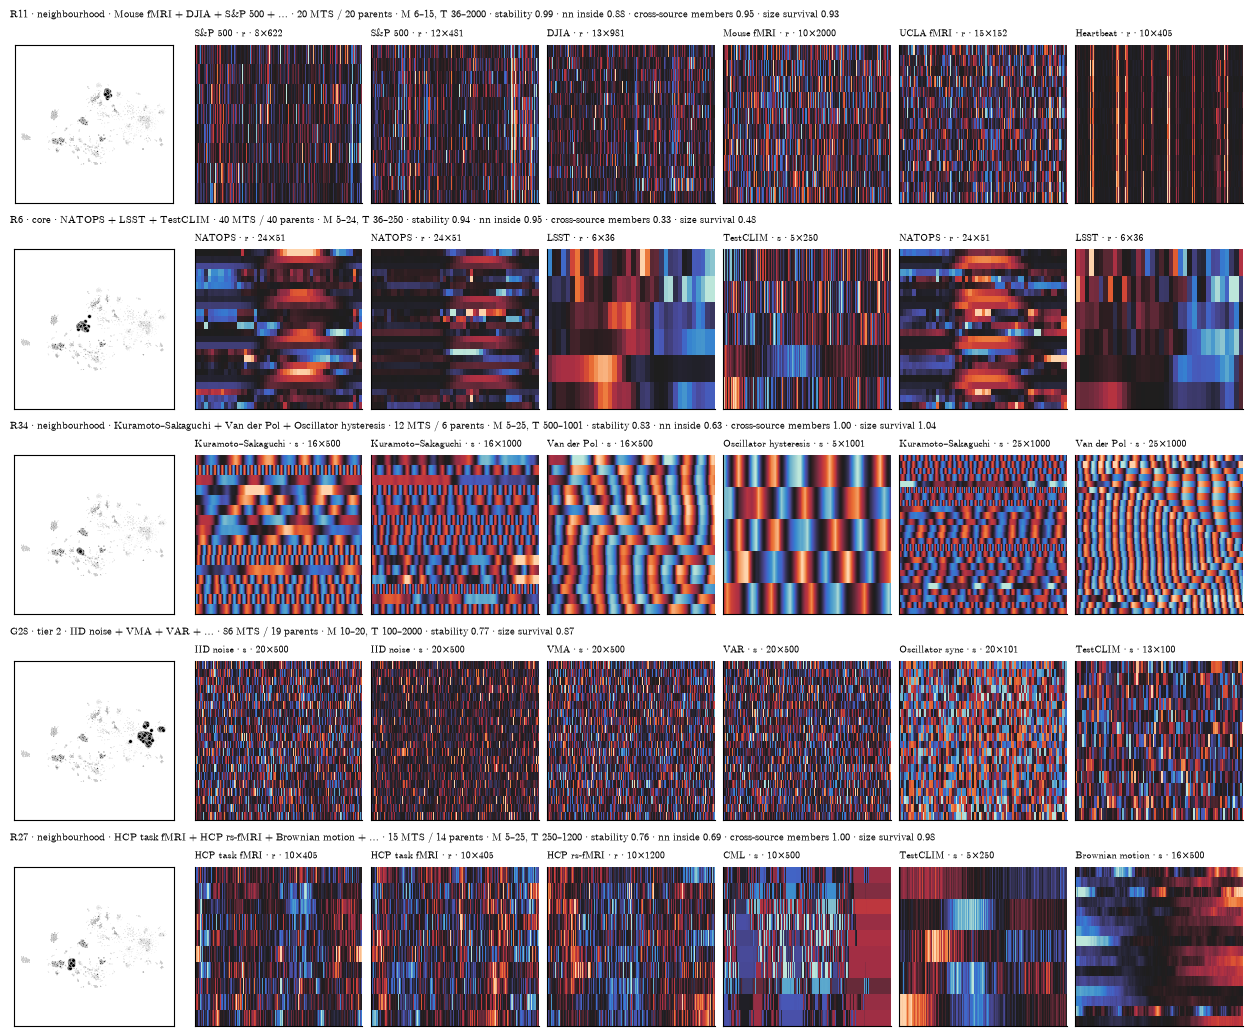

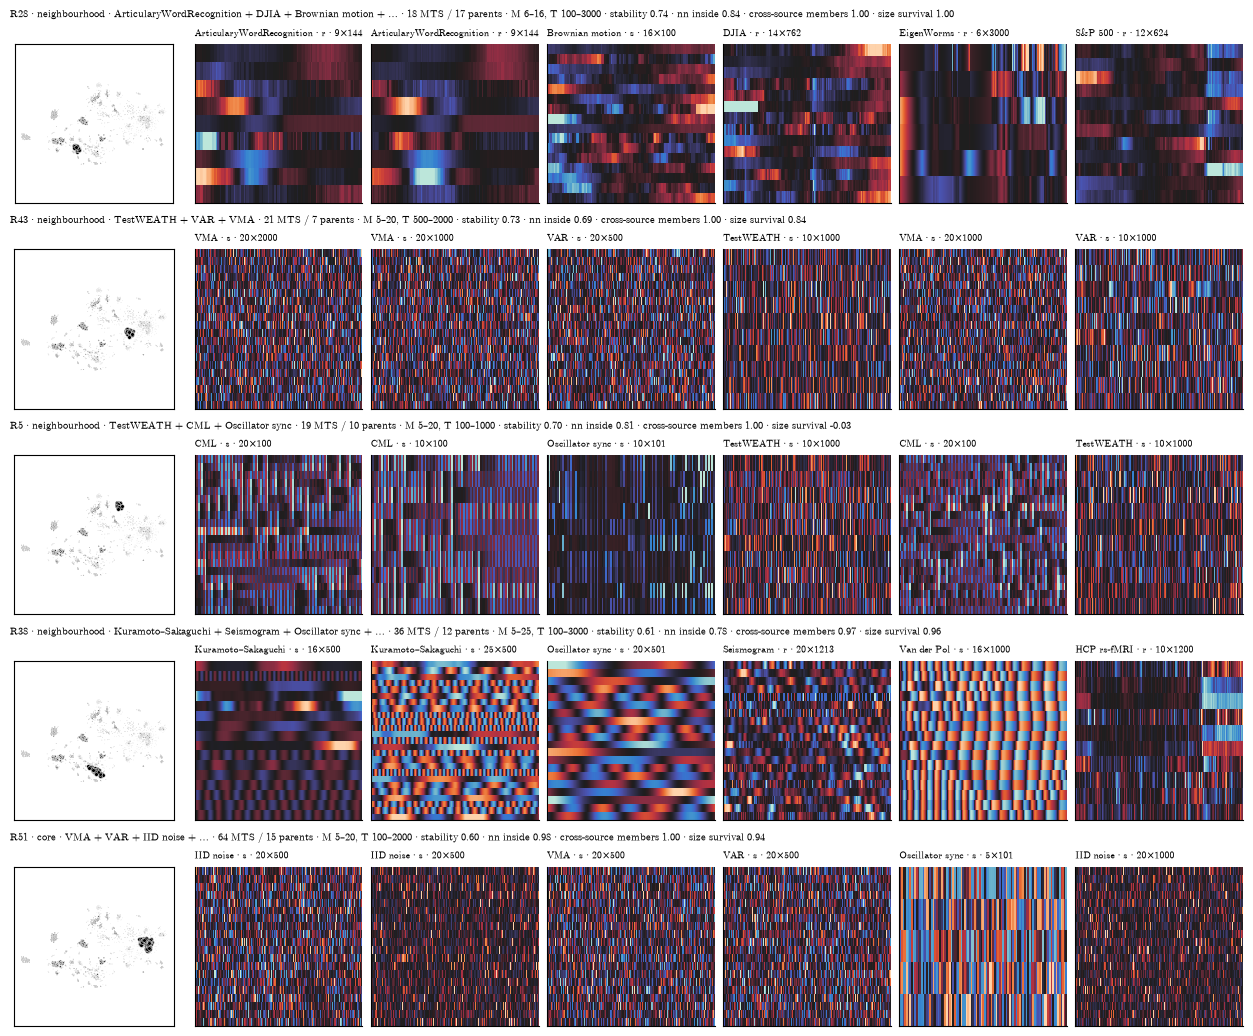

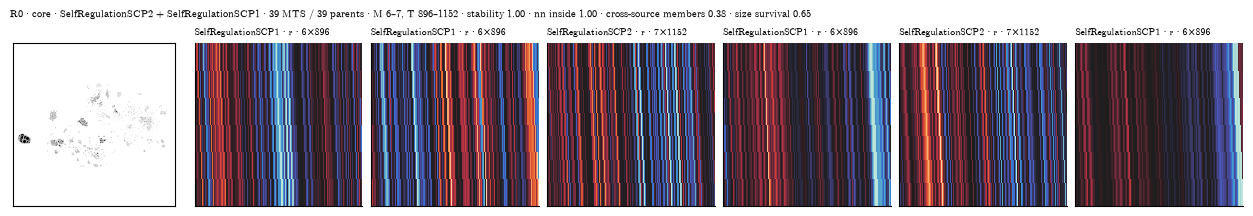

In [11]:
def region_rows(units, n=6, width=12.5):
    for chunk in [units[i:i + 5] for i in range(0, len(units), 5)]:
        fig = plt.figure(figsize=(width, 2.05 * len(chunk)), dpi=100)
        sub = fig.subfigures(len(chunk), 1, squeeze=False)[:, 0]
        for sf, (level, u) in zip(sub, chunk):
            labels = regions if level == "R" else density
            members = np.flatnonzero(labels == u)
            reps = ta.representatives(members, D, meta, n=n)
            axes = sf.subplots(1, n + 1, gridspec_kw={"width_ratios": [1.1] + [1] * n})
            ta.draw_groups(axes[0], xy, labels, [u])
            ta.plot_atlas(axes[0], xy, meta, annotate=False, shade=False, size=.12, faint=density < 0)
            axes[0].scatter(*xy[members].T, s=7, c="k", edgecolors="white", linewidths=.3, zorder=4)
            row = R.set_index("region").loc[u] if level == "R" else None
            head = (f"R{u} · {row.kind} · {row.title} · {row['size']} MTS / {row.parents} parents · M {row.M}, T {row['T']} · "
                    f"stability {row.stability:.2f} · nn inside {row.nn_inside:.2f} · cross-source members {row.cross_members:.2f} · "
                    f"size survival {row.size_survival:.2f}") if level == "R" else (
                    f"G{u} · tier {groups.loc[u, 'tier']} · {groups.loc[u, 'title']} · {groups.loc[u, 'size']} MTS / "
                    f"{groups.loc[u, 'parents']} parents · M {groups.loc[u, 'M']}, T {groups.loc[u, 'T']} · stability "
                    f"{groups.loc[u, 'stability']:.2f} · size survival {groups.loc[u, 'size_survival']:.2f}")
            sf.suptitle(head, fontsize=7.5, x=.01, ha="left")
            for ax, r in zip(axes[1:], reps):
                m = meta.iloc[r]
                ta.heatmap(ax, corpus["arrays"][m.dataset], f"{m.source} · {m.origin[0]} · {m['M']}×{m['T']}")
            for ax in axes[1 + len(reps):]:
                ax.axis("off")
        plt.show()

gallery = show[show.priority.str[0].isin(["A", "B"]) & show.covered_by.isna()]
units = [(u[0], int(u[1:])) for u in gallery.unit]
region_rows(units)

## 6. Signatures of the candidates

The table gives median z on the case-study SPI pairs and median raw-series descriptors for each candidate, next to the corpus medians. The raw descriptors check a reading against the data; they are not features of the representation.

In [12]:
axes_z = ta.case_axes(corpus["raw"], corpus["spis"])
raw = pd.DataFrame([ta.raw_descriptors(corpus["arrays"][n]) for n in meta.dataset])
mask = {u: (regions if u[0] == "R" else density) == int(u[1:]) for u in gallery.unit}
sig = pd.concat({"case axes (median z)": pd.DataFrame({u: axes_z[m].median() for u, m in mask.items()}).T,
                 "raw series (median)": pd.DataFrame({u: raw[m].median() for u, m in mask.items()}).T}, axis=1)
corpus_row = pd.concat({"case axes (median z)": axes_z.median(), "raw series (median)": raw.median()}).to_frame("corpus").T
sig = pd.concat([sig, corpus_row])
sig.insert(0, "title", list(gallery.title) + [""])
sig.round(2)

title     case axes (median z)                                                                                              \
                                                                 r–ρ (linear vs monotone) r–MI (linear vs general) r–max xcorr (zero lag vs best lag) r–coherence (time vs frequency)   
R11                              Mouse fMRI + DJIA + S&P 500 + …                     0.98                     0.88                               0.99                            0.92   
R6                                      NATOPS + LSST + TestCLIM                     0.98                     0.34                               0.78                            0.39   
R34     Kuramoto–Sakaguchi + Van der Pol + Oscillator hysteresis                     1.00                     0.62                               0.50                            0.04   
G28                                    IID noise + VMA + VAR + …                     0.95                     0.03                               0.04                           -0.00   
R27            HCP task fMRI + HCP rs-fMRI + Brownian motion + …                     0.99                     0.73                               0.93                            0.50   
R28       ArticularyWordRecognition + DJIA + Brownian motion + …                     0.97                     0.38                               0.87                            0.20   
R43                                        TestWEATH + VAR + VMA                     0.98                     0.03                              -0.06                           -0.02   
R5                             TestWEATH + CML + Oscillator sync                     1.00                     0.67                               0.64                            0.73   
R38        Kuramoto–Sakaguchi + Seismogram + Oscillator sync + …                     0.99                    -0.04                               0.12                            0.01   
R51                                    VMA + VAR + IID noise + …                     0.95                     0.03                               0.04                            0.00   
R0                       SelfRegulationSCP2 + SelfRegulationSCP1                     1.00                     0.96                               0.76                            0.63   
corpus                                                                               0.97                     0.30                               0.59                            0.26   

                                            raw series (median)                                                                        
       Euclid–DTW (aligned vs warped shape)                lag1 trend_r2 negative_share_strong pc1_share repeat_fraction max_robust_z  
R11                                    0.77               -0.02     0.00                  0.00      0.39            0.00         5.10  
R6                                     0.91                0.96     0.07                  0.11      0.62            0.00         8.61  
R34                                    0.43                1.00     0.00                  0.32      0.28            0.00         1.53  
G28                                    0.05               -0.00     0.00                  0.50      0.11            0.00         4.25  
R27                                    0.88                0.71     0.12                  0.00      0.40            0.00         4.57  
R28                                    0.89                0.99     0.47                  0.07      0.55            0.22         6.42  
R43                                   -0.03               -0.09     0.00                  0.50      0.13            0.00         4.12  
R5                                     0.35               -0.68     0.00                  0.08      0.31            0.00         3.57  
R38                                    0.38                1.00     0.01                  0.50      0.29    

## 7. Readings

Numbers come from the tables above. "Size survival" is the share of a unit's tightness, relative to random sets, that remains against sets matched on (log M, log T): 1 means size explains none of it. Enrichment q values use the primary setting (k = 10, 3 × 3 size strata) unless stated. Readings name a shared organisation of dependence. Where a reading goes beyond the numbers, it is marked as inference.

**Cross-domain, real–real**
- **R11 · mouse fMRI (9 subjects), DJIA and S&P 500 log-returns (7 market windows; all `-lr` arrays), with two LSST, one UCLA fMRI and one Heartbeat recording.** 20 recordings from 20 parents; M 6–15, T 36–2000.
  - The region is stable at .99 when the map is re-embedded on parent subsets. 88% of members' feature-space neighbours fall inside it, and 95% of members have a neighbour from another source inside it. Size explains little (survival .93).
  - Signature: every r-based axis near 1 (r–MI .88, r–max xcorr .99, r–coherence .92), no negative strong edges, and temporally white channels (lag-1 −.02). That is linear, contemporaneous, positive dependence between unpredictable signals.
  - Reading (inference): a common instantaneous factor over white fluctuations, as with a market factor in returns or a global signal in fMRI.
  - Its density core (G17) sits at stability .74, inside Hennig's "pattern" band. The map region is far more stable than the core's exact membership.
  - At family level the mouse–market enrichment depends on stratification: about 5× (q ≈ .2) with 3 × 3 strata, 14–18× (q ≤ .012) with 4 × 4 strata at k ≥ 10. Disclose this as setting-dependent.

**Cross-model, synthetic**
- **R34 · Kuramoto–Sakaguchi (3 configurations), Van der Pol (2) and one hysteresis oscillator.** M 5–25, T 500–1001.
  - Stability .83, size survival 1.04, and every member has an in-region neighbour from another model.
  - Signature: smooth (lag-1 1.00); zero-lag r does not track coherence (.04) and only partly tracks best-lag correlation (.50).
  - Reading (inference): coupling carried at a phase lag, which zero-lag measures miss.
  - Kuramoto–Van der Pol is the strongest robust family enrichment: 63–283× with q ≤ .06 at every k without stratification and with 3 × 3 strata, and weaker (q .09–.34) with 4 × 4 strata.

**Cross-domain, model–real**
- **R38 · Kuramoto–Sakaguchi (3 configurations), oscillator synchrony (2), seismograms (3 stations), with single AWR, EigenWorms, HCP rest and Van der Pol members.** M 5–25, T 100–3000.
  - Same family of signature as R34 but more extreme: r–MI −.04, r–max xcorr .12, r–coherence .01, and half the strong edges negative.
  - Seismograms neighbour Kuramoto–Sakaguchi 14× more often than expected (q .12 primary).
  - Stability .61, at the bottom of the pattern band; survival .96.
  - Reading (inference): oscillatory channels whose relations are lagged or in anti-phase, so zero-lag r says little about the rest of the dependence.
- **R28 · ArticularyWordRecognition (10), DJIA price levels (3 windows) and arithmetic Brownian motion (2 windows of one configuration), with Cricket, EigenWorms and S&P price members.** M 6–16, T 100–3000.
  - Stability .74, survival 1.00.
  - Signature: persistent (lag-1 .99), trending (trend R² .47), contemporaneous and best-lag correlation agree (.87), and linear and general dependence diverge (r–MI .38).
  - Brownian motion neighbours AWR 52× (q .018) and Cricket 43× (q .012), and DJIA 26× (q .07).
  - Reading: co-trending. Integrated or trending channels give large, unstable sample correlations whether or not the channels are coupled (Yule 1926; Granger & Newbold 1974). The shared organisation is real, but it is a regime of nonstationarity, not a coupling form. Present it that way.
- **FingerMovements with oscillator synchrony** (family level, 29×, 18 parent pairs, q ≤ .022 at every stratified setting). FingerMovements has the anti-correlated channel pairs seen in the consensus notebook. A shared anti-phase reading is plausible but unchecked; inspect it before use.

**One system, two observables.** Four of the market windows appear twice: as log-returns in R11 and as price levels in R28 (DJIA 2012-09-10, 2016-08-03 and 2018-07-31; S&P 2018-04-03). The underlying system is the same, yet the two transforms land in different neighbourhoods with different signatures: a common instantaneous factor in returns, co-trending in prices. z follows the dependence organisation of what is measured, not the identity of the source. This is a direct, low-cost illustration for the paper.

**Within one programme or class**
- **R27 · HCP task and resting fMRI (11), with Brownian motion, CML and TestCLIM members.** Stability .76, survival .98. Mostly one acquisition programme, so it is weak evidence against the dataset objection.
- **R43 and R51 / G28 · linear-stochastic processes (VAR, VMA, IID noise, TestWEATH).** Every case axis is near 0. This is the "little or no dependence" region: stable and size-robust, but its sharing is the absence of structure.
- **R0 · SCP1 and SCP2 EEG.** Two datasets from one paradigm. This is a same-source check, not cross-domain evidence.
- **R6 · NATOPS with two LSST recordings.** Size survival .48. It is a NATOPS core with visitors.

**Cautionary**
- **R5 · TestWEATH, CML and oscillator synchrony** (anti-persistent, lag-1 −.68). It is tight and multi-source, but size-matched sets are as cohesive (survival −.03). Its co-location is what recording size predicts.

**What this supports.** Several validated, multi-source, size-heterogeneous neighbourhoods exist. In each, the shared reading is visible on interpretable axes:
- common instantaneous factor (R11);
- phase-lagged oscillation (R34, R38);
- co-trending (R28).

That backs the claim that z groups recordings by how their dependence is organised across generators, domains and sizes. Two qualifications should be stated, not hidden:
- co-trending is a shared regime rather than a coupling form;
- R5 shows that a multi-source group can still be size-driven.

## 8. Candidate map and composition

The paper-style map shows the priority A and B candidates: multi-source by parent recordings, and validated in feature space. They are filled and outlined over the corpus.

When a map region and a density group cover the same recordings, the map region is drawn, because it is the unit a reader sees. Its density group is its core (see `covered_by` and the region table). Each label sits on the island that holds most of the unit's members.

The earlier drawing, which drew density groups first, is saved as `candidate-map-groups-first` and shown below for comparison.

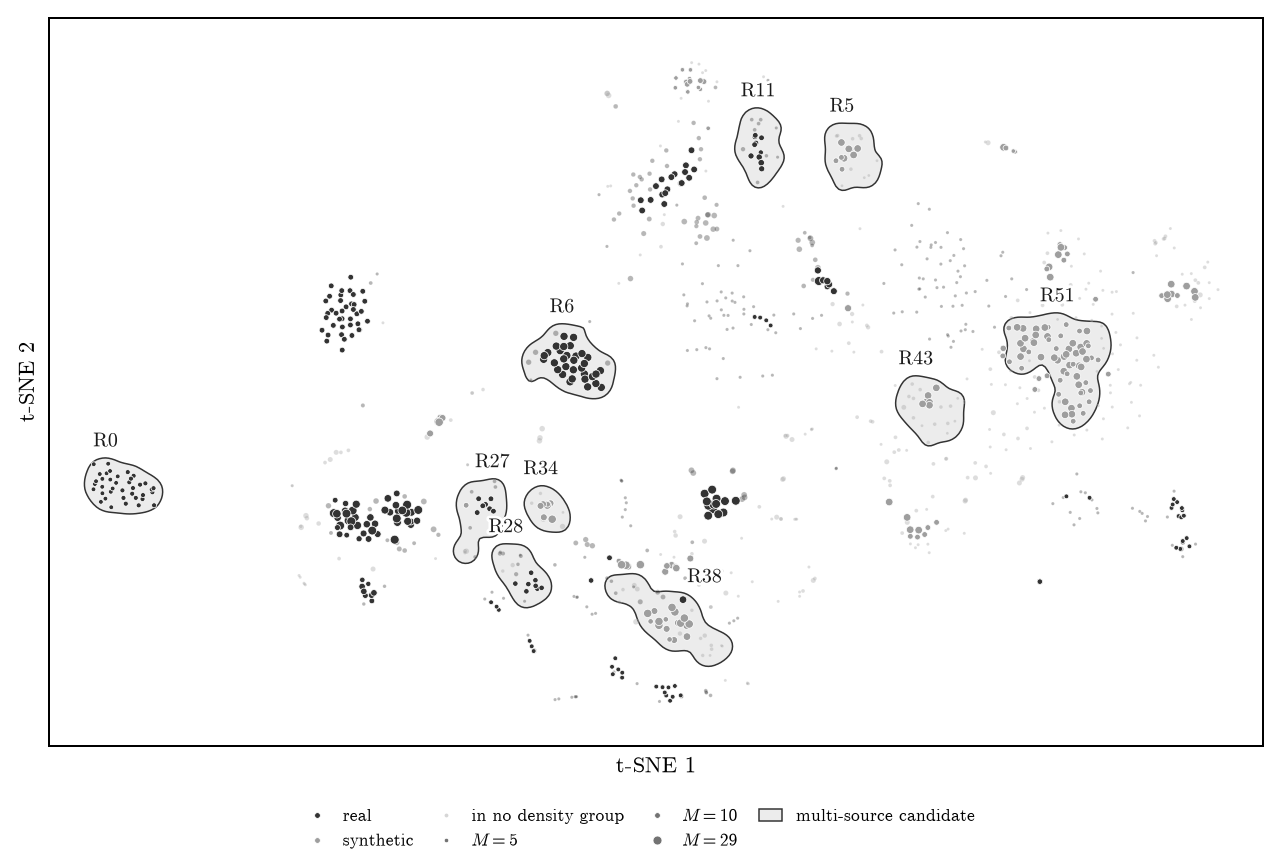

Drawn: R11, R6, R34, R27, R28, R43, R5, R38, R51, R0


In [13]:
def candidate_map(order, name, width=7.0):
    lab, names = np.full(len(meta), -1), {}
    for i, (level, u) in enumerate(order):
        m = (regions if level == "R" else density) == u
        new = m & (lab < 0)
        if new.sum() >= max(3, .5 * m.sum()):  # a unit mostly drawn already is not drawn twice
            lab[new] = i
            names[i] = f"{level}{u}"
    span = xy.max(0) - xy.min(0)
    fig, ax = plt.subplots(figsize=(width, width * span[1] / span[0] + .9))
    ta.draw_groups(ax, xy, lab, list(names))
    ta.plot_atlas(ax, xy, meta, faint=density < 0, size=.8, annotate=False, shade=False, square=False)
    ax.set(xlabel="t-SNE 1", ylabel="t-SNE 2")
    ta.place_labels(ax, xy, lab, names, avoid=density >= 0)
    ta.atlas_legend(fig, meta, size=.8, filled="multi-source candidate", dashed=None)
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=600 if ext == "png" else None)
    return fig, names

regions_first = sorted(units, key=lambda u: u[0] != "R")  # stable sort keeps the priority order within each level
fig, drawn = candidate_map(regions_first, "candidate-map")
plt.show()
print("Drawn:", ", ".join(drawn.values()))
assert set(drawn.values()) == {f"R{r}" for r in R.region[R.candidate]}, "explorer v4 candidates must match this map"

**Composition.** Each drawn candidate gets one bar showing its members by source family, dark for real and light for synthetic, as on the map. Bars show shares. The right-hand column gives the member count, the number of parent recordings, and any sources too small to label inside the bar.

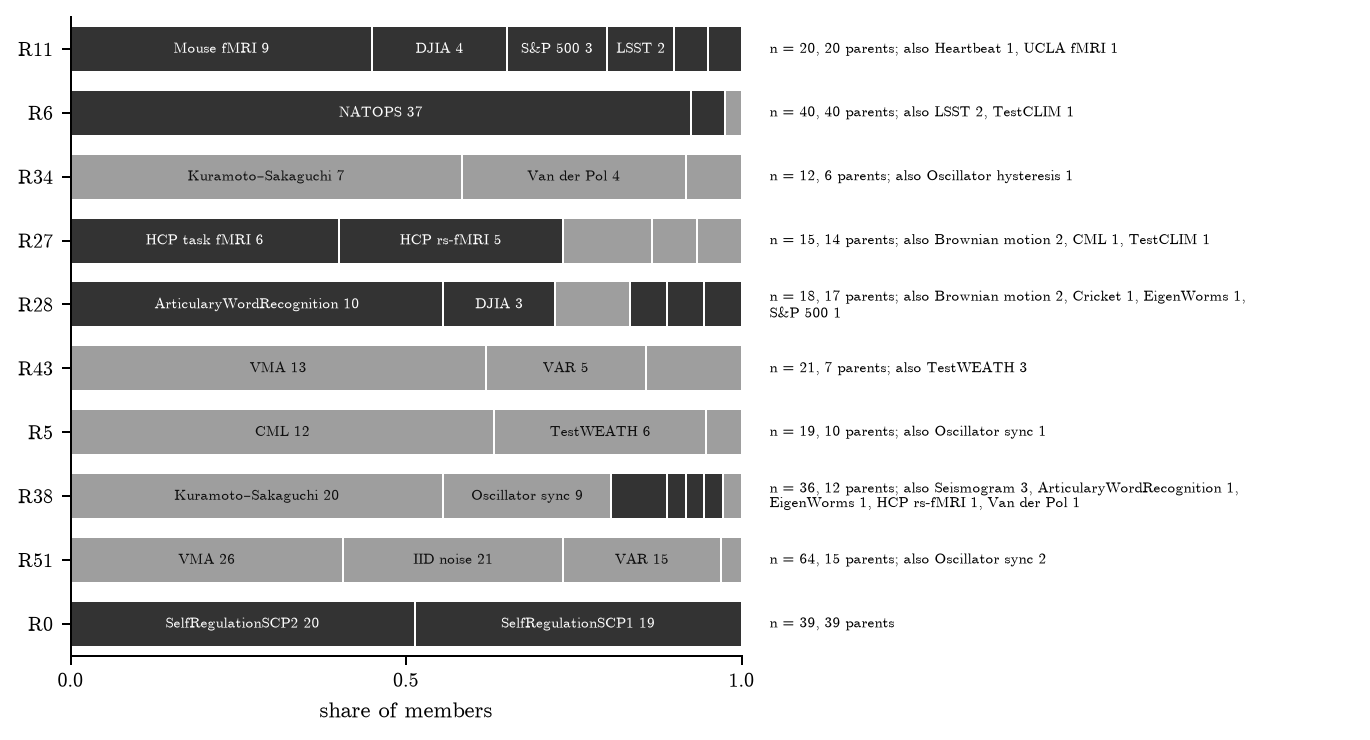

In [14]:
import textwrap

def composition(order, name):
    rows = [(f"{level}{u}", meta[(regions if level == "R" else density) == u]) for level, u in order]
    fig, (ax, side) = plt.subplots(1, 2, figsize=(7.5, .34 * len(rows) + .6), gridspec_kw={"width_ratios": [1.15, 1]})
    side.axis("off")  # the right-hand column; its texts stay out of the layout, so measured label widths are final
    pending = []
    for i, (unit, m) in enumerate(rows):
        parts = (m.groupby("source").agg(n=("dataset", "size"), parents=("parent", "nunique"), origin=("origin", "first"))
                 .sort_values(["n", "parents"], ascending=False))
        left = 0.
        for source, r in parts.iterrows():
            share = r.n / len(m)
            ax.barh(i, share, left=left, height=.72, color=ta.ORIGIN_FILL.get(r.origin, "white"), edgecolor="white", lw=.8)
            pending.append((i, left, share, f"{source} {r.n}", r.origin))
            left += share
    ax.set(yticks=range(len(rows)), yticklabels=[u for u, _ in rows], xlim=(0, 1), ylim=(len(rows) - .5, -.5), xticks=[0, .5, 1],
           xlabel="share of members")
    fig.draw_without_rendering()
    renderer, small = fig.canvas.get_renderer(), {i: [] for i in range(len(rows))}
    for i, left, share, label, origin in pending:  # label inside a segment only where it fits, else list it on the right
        text = ax.text(left + share / 2, i, label, ha="center", va="center", fontsize=6, color="white" if origin == "real" else "0.05")
        span = ax.transData.transform([(left, i), (left + share, i)])[:, 0]
        if text.get_window_extent(renderer).width > .92 * (span[1] - span[0]):
            text.remove()
            small[i].append(label)
    side.set_ylim(ax.get_ylim())
    for i, (unit, m) in enumerate(rows):
        note = f"n = {len(m)}, {m.parent.nunique()} parents" + (f"; also {', '.join(small[i])}" if small[i] else "")
        side.text(0, i, textwrap.fill(note, 68), va="center", fontsize=6, linespacing=1.1, in_layout=False)
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=600 if ext == "png" else None, bbox_inches="tight")
    return fig

composition([(n[0], int(n[1:])) for n in drawn.values()], "candidate-composition")
plt.show()

Previous drawing, density groups first. G28 is drawn instead of R51 and keeps its three islands, and the other units are unchanged.

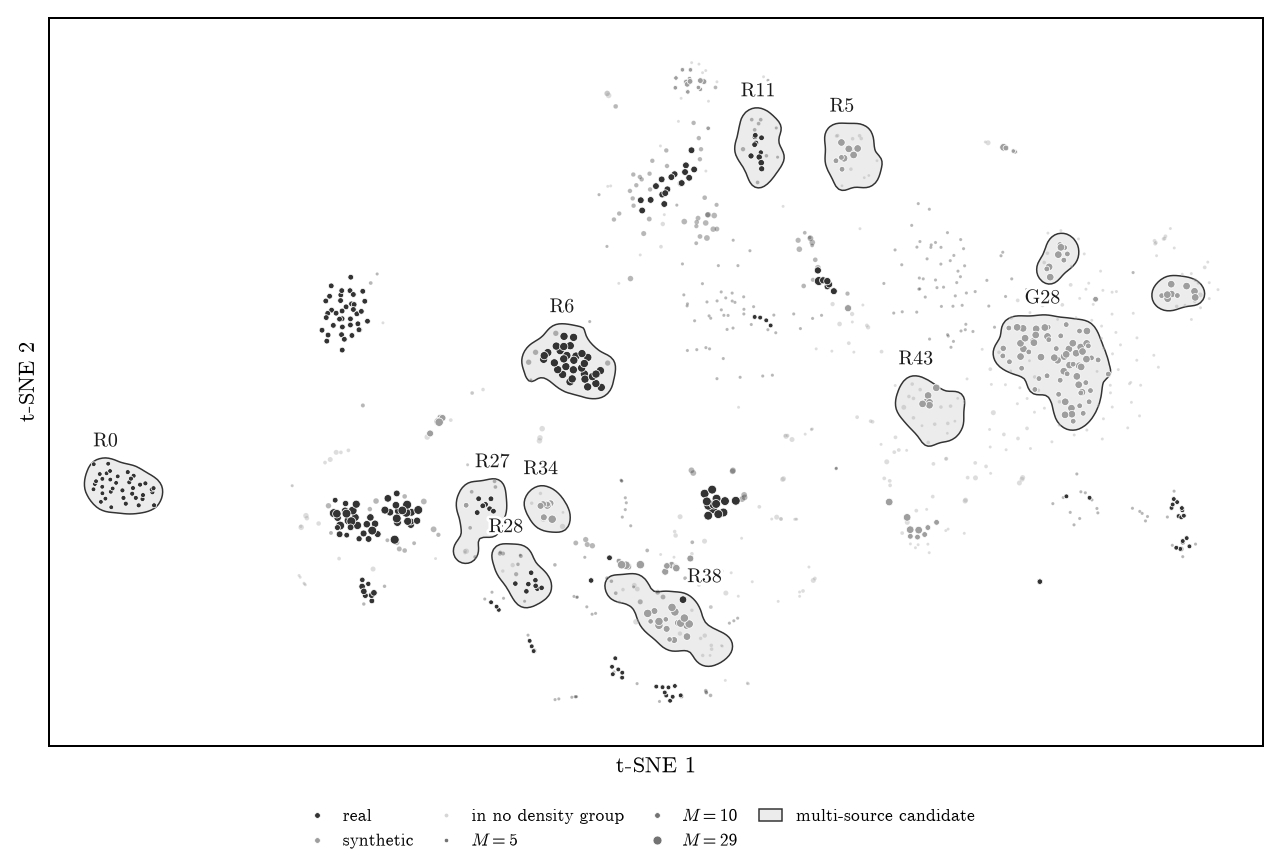

In [15]:
fig, _ = candidate_map(units, "candidate-map-groups-first")
plt.show()

## 9. Reproduction

```bash
.venv/bin/python -m research.zenodo.atlas.neighbourhood_atlas   # about 5 minutes; needs the tsne-261021 and consensus-261024 caches
.venv/bin/jupyter nbconvert --to notebook --execute --inplace research/zenodo/atlas/notebooks/zenodo_1053_neighbourhoods_261024.ipynb
```

Outputs are in `results/zenodo_7118947/neighbourhoods-261024/`: `enrichment.csv` (every k × bins × family pair), `regions.csv`, `density-robustness.csv`, `neighbourhoods.npz` (edges, replicate Jaccards) and `figures/`.

In [16]:
import json
print(json.dumps({k: v for k, v in N["manifest"].items() if k != "config"}, indent=1))

{
 "chosen_map": "pca50-p50-x1",
 "eligible_maps": [
  "pca50-p10-x1",
  "pca50-p10-x2",
  "pca50-p20-x1",
  "pca50-p20-x2",
  "pca50-p30-x1",
  "pca50-p50-x1",
  "pca50-p80-x1",
  "pca100-p20-x1",
  "pca100-p30-x1",
  "pca100-p50-x1"
 ],
 "seconds": 126.84336791699752,
 "script_sha256": "e02db1cf05f0888adee7459fbb67514c864a165c742725d240c0da86ef94813e",
 "consensus_manifest_sha256": "b4d9f94e7d90bc75eb7ab1bec99e14286ed0f63d0b6af6f85a6a1d5e5f630954"
}
